# US earnings strategy: reproducible pilot

## tl;dr

This notebook reruns the registered strategy from cached original disclosures and price data. It makes no network requests and places no orders.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Markdown, display
from us_earnings.research import run_research
get_ipython().run_line_magic("matplotlib", "inline")

ROOT = Path.cwd()
if not (ROOT / "configs/pilot-v1.json").exists():
    ROOT = ROOT.parent
CONFIG_FILE = ROOT / "configs/pilot-v1.json"
result = run_research(ROOT, CONFIG_FILE)
later = result["summary"].loc[result["summary"].period.str.contains("later evaluation")].set_index("arm")
guidance = later.loc["guidance"]
ml = later.loc["ml"]
market = later.loc["spy"]
display(Markdown(
    f"**2024–2025 annualized returns after assumed costs:** raised guidance + price "
    f"{guidance.cagr:.2%}; ML guidance + price {ml.cagr:.2%}; SPY {market.cagr:.2%}. "
    f"The guidance strategy averaged {guidance.average_exposure:.1%} invested exposure "
    f"and closed {int(guidance.trades)} trades. These portfolios have different exposure and risk.\n\n"
    "**Capital decision: defer allocation.** This is a convenience-sample historical pilot, "
    "with weak text labels and no prospective performance record. The local ML model is a "
    "TF-IDF logistic classifier, not a generative LLM."
))

**2024–2025 annualized returns after assumed costs:** raised guidance + price 0.54%; ML guidance + price 1.55%; SPY 21.28%. The guidance strategy averaged 0.7% invested exposure and closed 2 trades. These portfolios have different exposure and risk.

**Capital decision: defer allocation.** This is a convenience-sample historical pilot, with weak text labels and no prospective performance record. The local ML model is a TF-IDF logistic classifier, not a generative LLM.

## Context & Methods

The question is whether an earnings event and a raised-guidance filter improve a simple price rule. The portfolio starts at one normalized unit; no account-size assumption is needed.

### Key Assumptions

- Fixed sample of 24 surviving US companies; this is not a historical index universe.
- Research window: 2019–2025; development: 2019–2022; validation: 2023; later evaluation: 2024–2025.
- An event becomes a signal at the close of the first benchmark session strictly after its SEC filing date. Entry occurs at the next session open. Actual earnings publication may have been earlier.
- Price confirmation: close above a trailing 50-session average, with that session's return above SPY's return.
- Position target: 10% of current opening NAV, up to 10 positions, no leverage. Candidates rank by prior-session relative return, with ticker as a tie-breaker.
- Exit: close of the twentieth holding session, or a fixed stop two trailing 20-session ATRs below the entry open. An opening gap through a stop fills at the worse open, before costs. Entry-day stops are allowed.
- Costs: 10 basis points each side; diagnostics use 5, 20 and 50 basis points. Cash earns zero; taxes are excluded.
- Alpaca SIP prices are adjusted for splits, cash dividends and spin-offs. Returns use fractional adjusted units. Stops are total-return-unit approximations, not reconstructed historical broker orders.
- The lexical baseline detects explicit raised annual guidance language. Numeric-only revisions can be missed.
- The ML classifier fits only pre-2023 disclosure text and lexical weak labels. It never trains on returns. The fixed 0.5 score threshold is not a calibrated probability.
- The later period is not a fully blind holdout: the universe was chosen today and text parsing was audited across years before inspecting trading returns. Sensitivities are diagnostics, not strategy selection.

In [2]:
config = result["config"]
display(pd.DataFrame({"Parameter": ["Holding sessions", "Stop ATR multiple", "Cost per side (bps)",
                                   "Maximum positions", "Target position fraction"],
                      "Value": [config["holding_sessions"], config["stop_atr_multiple"],
                                config["cost_bps_per_side"], config["max_positions"],
                                config["position_fraction"]]}))

,Parameter,Value
0,Holding sessions,20.0
1,Stop ATR multiple,2.0
2,Cost per side (bps),10.0
3,Maximum positions,10.0
4,Target position fraction,0.1


## Data

Original SEC Item 2.02 filings provide event dates and earnings exhibits. Alpaca consolidated SIP bars provide daily OHLC. Raw responses, URLs, fetch times and SHA-256 hashes are retained locally. Missing exhibits stay in the coverage denominator and cannot enter event strategies.

Source documentation: [SEC APIs](https://www.sec.gov/search-filings/edgar-application-programming-interfaces), [Alpaca historical bars](https://docs.alpaca.markets/us/reference/stockbars).

In [3]:
manifest = result["manifest"]
display(Markdown(f"**Price rows:** {manifest['prices']['rows']:,}; "
                 f"**catalog filings:** {manifest['events']['catalog_filings']:,}; "
                 f"**retrieved exhibits:** {manifest['events']['retrieved']:,}; "
                 f"**explicit guidance raises:** {manifest['events']['explicit_raises']:,}."))
display(result["coverage"].rename(columns={"filings": "Catalog filings", "retrieved": "Retrieved",
                                          "explicit_raises": "Explicit raises", "missing": "Missing"}))

**Price rows:** 46,625; **catalog filings:** 683; **retrieved exhibits:** 681; **explicit guidance raises:** 79.

,Catalog filings,Retrieved,unclassified,Explicit raises,Missing
ticker,,,,,
AAPL,29,29,0,0,0
ADBE,28,28,0,0,0
AMZN,28,28,0,0,0
CAT,29,28,1,0,0
CRM,28,28,0,14,0
CSCO,28,28,0,3,0
DE,28,28,0,7,0
FDX,30,29,1,3,0
GOOGL,29,29,0,0,0


### Source preview

The preview preserves exact event identity and original-document links. It is a sample, not a validation of every extracted label.

In [4]:
preview = result["events"].loc[result["events"].raised_guidance,
                                  ["ticker", "filingDate", "accessionNumber", "guidance_state", "source_url"]].head(5)
display(preview)
display(pd.DataFrame([manifest["text_model"]], columns=["training_rows", "positive_training_rows",
                                                       "training_last_date", "later_predictions", "later_positives"]))

,ticker,filingDate,accessionNumber,guidance_state,source_url
157,CSCO,2022-11-16,0001193125-22-286782,explicit_annual_raise,https://www.sec.gov/Archives/edgar/data/858877...
158,CSCO,2023-02-15,0001193125-23-040212,explicit_annual_raise,https://www.sec.gov/Archives/edgar/data/858877...
159,CSCO,2023-05-17,0001193125-23-147021,explicit_annual_raise,https://www.sec.gov/Archives/edgar/data/858877...
170,CRM,2019-03-04,0001108524-19-000007,explicit_annual_raise,https://www.sec.gov/Archives/edgar/data/110852...
171,CRM,2019-06-04,0001108524-19-000022,explicit_annual_raise,https://www.sec.gov/Archives/edgar/data/110852...


,training_rows,positive_training_rows,training_last_date,later_predictions,later_positives
0,390,52,2022-12-20,291,81


## Results

### Portfolio comparison

These are funded, cash-constrained portfolio results. SPY and the sample buy-and-hold portfolio are fully invested, so their returns are not risk-matched to sparse earnings strategies. Trade counts below refer to trades closing in the selected period, including positions carried from the previous year.

In [5]:
columns = ["label", "cagr", "max_drawdown", "average_exposure", "trades", "win_rate"]
table = later.reset_index()[columns].rename(columns={"label": "Strategy", "cagr": "Annualized return",
    "max_drawdown": "Maximum drawdown", "average_exposure": "Average exposure", "trades": "Closed trades",
    "win_rate": "Winning trades"})
display(table.style.format({"Annualized return": "{:.2%}", "Maximum drawdown": "{:.2%}",
                           "Average exposure": "{:.1%}", "Closed trades": "{:.0f}",
                           "Winning trades": "{:.1%}"}, na_rep="—").hide(axis="index"))

Strategy,Annualized return,Maximum drawdown,Average exposure,Closed trades,Winning trades
Price only,7.67%,-17.77%,87.6%,342,45.0%
Earnings + price,4.16%,-5.71%,19.5%,63,54.0%
Raised guidance + price,0.54%,-0.38%,0.7%,2,100.0%
ML guidance + price,1.55%,-1.26%,4.3%,14,64.3%
SPY buy and hold,21.28%,-18.75%,100.0%,—,—
Sample buy and hold,14.32%,-20.43%,100.0%,—,—


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


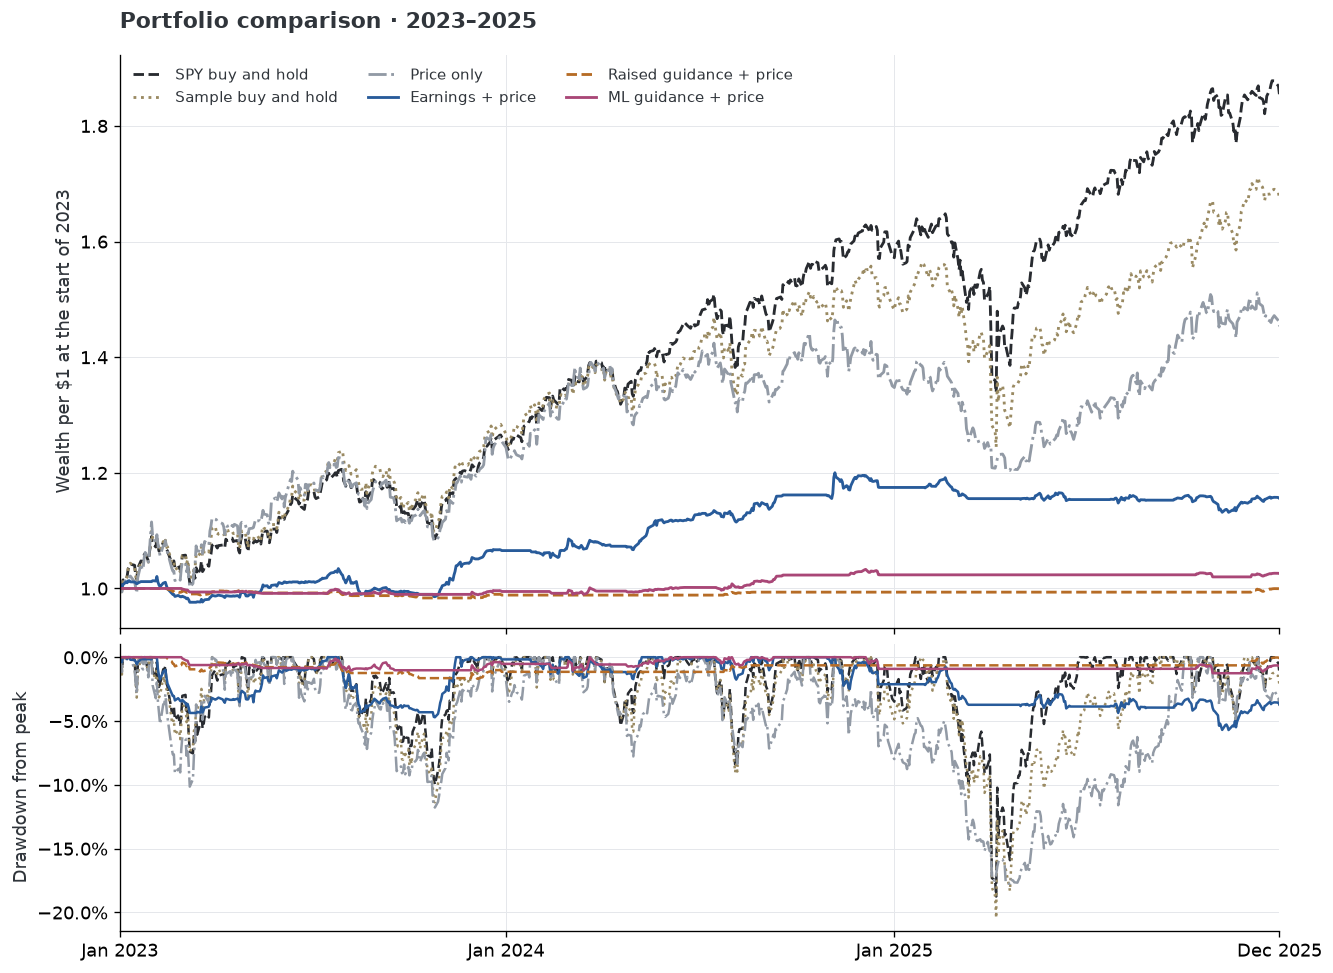

In [6]:
import matplotlib.pyplot as plt
from us_earnings.figures import equity_figure, event_figure, exposure_figure
OUT = ROOT / "artifacts" / result["config"].get("artifact_subdir", "")
display(equity_figure(result, OUT))
plt.close("all")

The common plot starts in 2023 because the ML model is trained through 2022. Every curve is rebased to wealth at the start of 2023. Earlier baseline histories remain in the CSV ledgers. The sample passive portfolio retains the weights that evolved from its 2019 purchases.

### Comparable event horizons

For each price-confirmed earnings event, compare the stock's next-open-to-twentieth-close return with SPY over the identical dates, applying the same assumed costs to both. These observations have no stops or portfolio capacity constraints. They are not annualized or treated as independent trades. Intervals resample whole signal months 2,000 times; they do not eliminate all dependence.

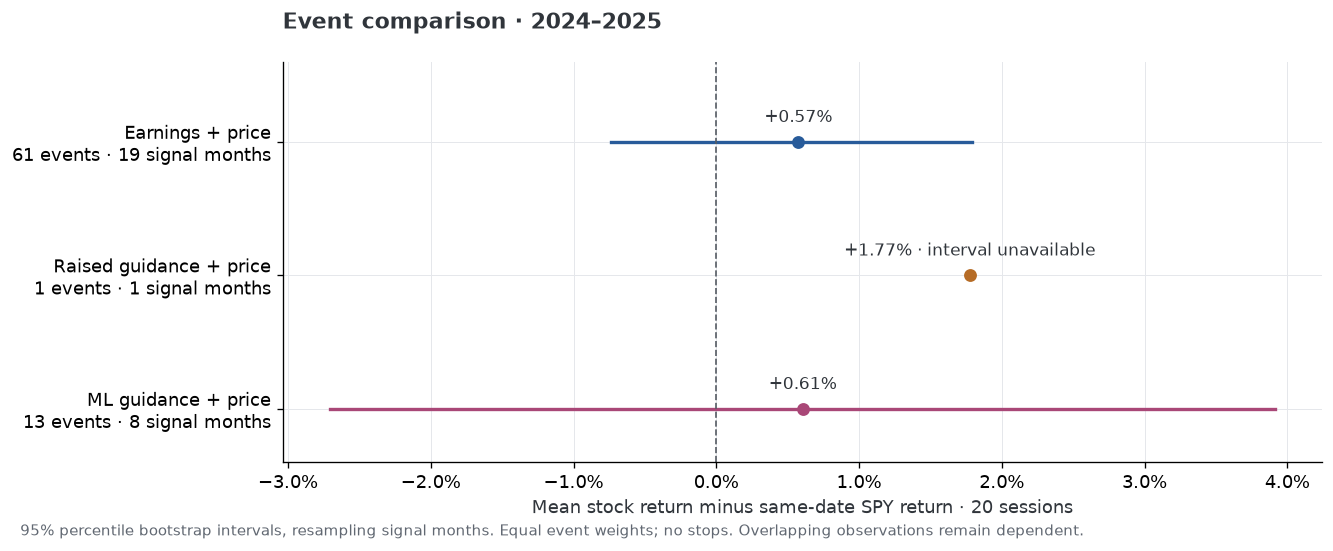

filter,events,months,mean_excess,lower_95,upper_95
earnings,61,19,+0.57%,-0.74%,+1.79%
guidance,1,1,+1.77%,Unavailable,Unavailable
ml,13,8,+0.61%,-2.71%,+3.91%


In [7]:
display(event_figure(result, OUT))
plt.close("all")
display(result["intervals"].loc[result["intervals"].period.str.contains("later evaluation")]
        [["filter", "events", "months", "mean_excess", "lower_95", "upper_95"]]
        .style.format({"mean_excess": "{:+.2%}", "lower_95": "{:+.2%}", "upper_95": "{:+.2%}"}, na_rep="Unavailable").hide(axis="index"))

### Exposure and concentration

A low drawdown can follow from holding substantial cash. Issuer concentration and the number of events matter when deciding whether a promising average is repeatable.

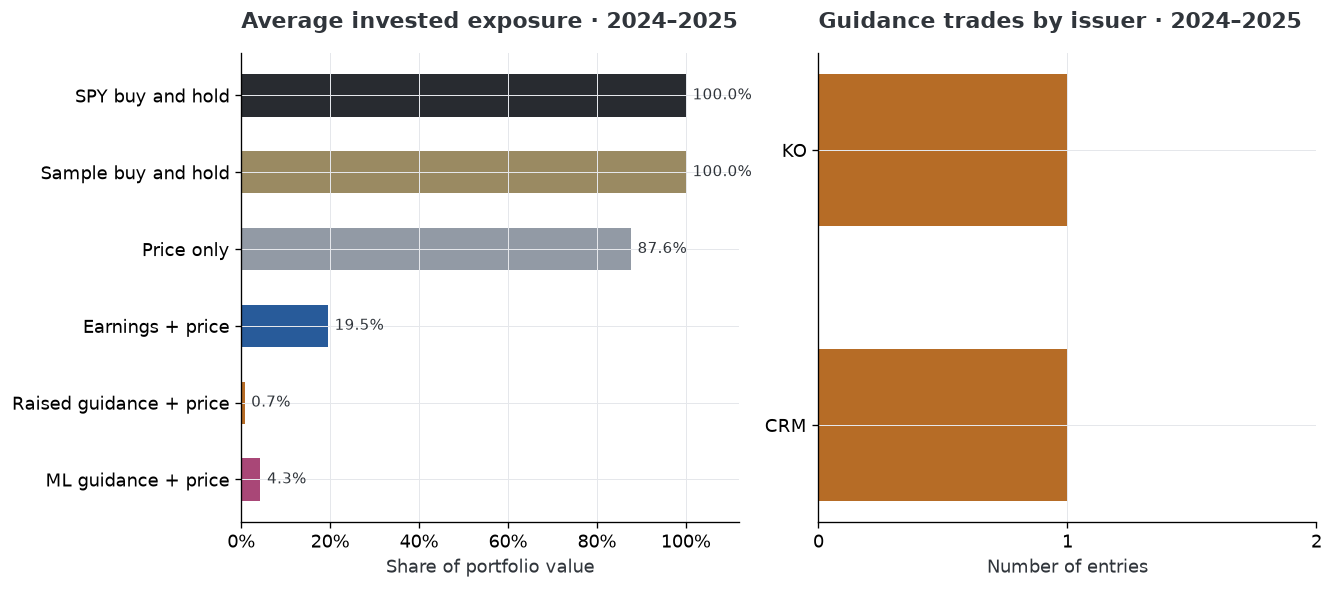

In [8]:
display(exposure_figure(result, OUT))
plt.close("all")

### Cost and holding-period diagnostics

The registered primary horizon remains 20 sessions. These diagnostic variants are not used to choose a winning configuration. ML cost results cover 2023–2025; other cost results cover 2019–2025.

In [9]:
display(result["stress"][["arm", "cost_bps_per_side", "cagr", "max_drawdown", "trades"]]
        .sort_values(["arm", "cost_bps_per_side"]).style.format(
            {"cagr": "{:.2%}", "max_drawdown": "{:.2%}"}).hide(axis="index"))
display(pd.read_csv(OUT / "horizon-sensitivity.csv")
        [["arm", "holding_sessions", "cagr", "max_drawdown", "trades"]]
        .style.format({"cagr": "{:.2%}", "max_drawdown": "{:.2%}"}).hide(axis="index"))

arm,cost_bps_per_side,cagr,max_drawdown,trades
earnings,5.000000,3.96%,-8.71%,258
earnings,10.000000,3.58%,-8.98%,258
earnings,20.000000,2.81%,-9.51%,258
earnings,50.000000,0.55%,-12.75%,258
guidance,5.000000,0.16%,-2.57%,32
guidance,10.000000,0.11%,-2.65%,32
guidance,20.000000,0.02%,-2.81%,32
guidance,50.000000,-0.26%,-3.30%,32
ml,5.000000,0.93%,-1.24%,22
ml,10.000000,0.85%,-1.26%,22


arm,holding_sessions,cagr,max_drawdown,trades
earnings,5,1.08%,-5.24%,258
guidance,5,0.25%,-0.97%,32
earnings,20,3.58%,-8.98%,258
guidance,20,0.11%,-2.65%,32
earnings,40,5.97%,-12.96%,256
guidance,40,0.31%,-3.60%,32


### Inspect a trade and reconcile accounting

In [10]:
ledger = result["ledgers"]["guidance"]
display(ledger.head(8)[["ticker", "signal_date", "entry_date", "exit_date", "net_return", "exit_reason", "accession"]])
checks = []
for arm, trades in result["ledgers"].items():
    curve = result["curves"][arm]
    residual = float(curve.nav.iloc[-1] - (1 + trades.pnl.sum()))
    assert abs(residual) < 1e-9, (arm, residual)
    assert curve.cash.min() >= -1e-9
    assert curve.positions.max() <= config["max_positions"]
    assert (trades.entry_date > trades.signal_date).all()
    checks.append({"Strategy": arm, "Ending NAV minus 1 + realized P&L": residual,
                   "Maximum positions": int(curve.positions.max()), "Closed trades": len(trades)})
display(pd.DataFrame(checks).style.format({"Ending NAV minus 1 + realized P&L": "{:.2e}"}).hide(axis="index"))

,ticker,signal_date,entry_date,exit_date,net_return,exit_reason,accession
0,CRM,2019-06-05,2019-06-06,2019-06-27,-0.064831,stop,0001108524-19-000022
1,TGT,2019-08-22,2019-08-23,2019-09-20,0.016122,time,0000027419-19-000018
2,JNJ,2019-10-16,2019-10-17,2019-10-18,-0.036347,stop,0000200406-19-000061
3,INTC,2019-10-25,2019-10-28,2019-11-22,0.025444,time,0000050863-19-000028
4,TGT,2019-11-21,2019-11-22,2019-12-03,-0.043711,stop,0000027419-19-000024
5,CRM,2020-08-26,2020-08-27,2020-09-04,-0.066411,stop,0001108524-20-000038
6,DE,2021-02-22,2021-02-23,2021-03-22,0.118615,time,0001558370-21-001244
7,WMT,2021-05-19,2021-05-20,2021-06-16,-0.033690,stop,0000104169-21-000037


Strategy,Ending NAV minus 1 + realized P&L,Maximum positions,Closed trades
price,-1.55e-15,10,1146
earnings,2.22e-16,9,258
guidance,2.22e-16,3,32
ml,-2.22e-16,3,22


## Takeaways

The pipeline supports reproducible historical comparisons, not a claim of profitable AI trading. The main unresolved issues are survivorship bias, incomplete numeric guidance extraction, weak ML labels, adjusted-unit execution assumptions, and absence of a prospective record.

Before deciding capital: obtain a historical universe including delisted firms; build a blinded human label sample with normalized guidance periods and accounting bases; replay raw corporate actions and fills; then freeze the strategy for prospective paper evaluation. Changing rules after reading these results requires a new protocol and a new evaluation sample.

All figures, trade ledgers, event audits, source failures and the environment lockfile accompany this notebook. Cached source data and fitted models are local artifacts and are excluded from Git.